# Figure 11: VDN policy realisation on `Cologne-v1`

Rolls out the best final-run VDN checkpoint (from `data/best_checkpoints/best_checkpoints.csv`)
on 1,000 episodes and plots one episode for one segment, chosen to show the main policy behaviours.
Output: `plotting/figures/Figure_11.pdf`.

In [1]:
import contextily as cx
import geopandas as gpd
import jax
import matplotlib as mpl
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from plotting.create_figures import PLOT_PARAMS
from rollout_data_generator import RolloutDataGenerator
from shapely.geometry import LineString, Point

plt.rcParams.update(PLOT_PARAMS)

MAP, ALG = "Cologne-v1", "vdn_rnn"
NUM_EPISODES, ROLLOUT_KEY = 1_000, 42

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [2]:
# Best checkpoint of the final runs, and rollouts
best = pd.read_csv("data/best_checkpoints/best_checkpoints.csv").drop_duplicates()
best = best[(best.map_name == MAP) & (best.algorithm == ALG)].iloc[0]
rdg = RolloutDataGenerator(
    MAP,
    ALG,
    test_num_envs=NUM_EPISODES,
    checkpoint_id=int(best.checkpoint_id),
    checkpoint_path=f"data/best_checkpoints/{best.run_dir}",
)
data = jax.tree.map(np.asarray, rdg.generate_rollout_data(jax.random.PRNGKey(ROLLOUT_KEY)))
env = rdg.road_env

returns = data["reward"].sum(axis=1)
print(f"Seed {best.seed}, checkpoint {best.checkpoint_id}")
print(f"Mean return {returns.mean():.4e} (logged evaluation: {best['mean']:.4e})")

Seed 200, checkpoint 21662
Mean return -1.0387e+10 (logged evaluation: -1.0391e+10)


In [3]:
# Episode and segment to show
# Chosen by inspection among episodes near the median return (episode 257 is at the median): the
# segment's traffic responds to maintenance, the budget rejects several of its proposed repairs,
# and the environment finally forces a replacement that overrides the policy's major repair.
episode, segment = 257, 51
ep = {k: v[episode] for k, v in data.items()}

rejected = ep["action"] != ep["applied_actions"]  # (T, N)
forced = ep["forced_repair_flags"].astype(bool)  # (T, N)
utilisation = ep["traffic_volumes"][0] / np.asarray(env.initial_capacities)
print(f"Episode {episode}: return {returns[episode]:.4e} "
      f"({(returns < returns[episode]).mean():.0%} of episodes are worse)")
print(f"Segment {segment}: initial volume/capacity {utilisation[segment]:.0%}")
print("  rejected proposals (t, proposed -> executed):",
      [(int(t), int(ep["action"][t, segment]), int(ep["applied_actions"][t, segment]))
       for t in np.where(rejected[:, segment])[0]])
print("  forced replacements at t =", np.where(forced[:, segment])[0].tolist())
print("  unsafe (failed) state at t =",
      np.where(ep["edge_states"][:, segment] == env.num_damage_states - 1)[0].tolist())
print("  network forced replacements (t: count):",
      {int(t): int(c) for t, c in enumerate(ep["forced_replace_constraint_applied"]) if c})

Episode 257: return -1.0305e+10 (51% of episodes are worse)
Segment 51: initial volume/capacity 84%
  rejected proposals (t, proposed -> executed): [(3, 2, 0), (4, 2, 0), (14, 1, 0), (38, 2, 0), (39, 2, 0), (43, 1, 0), (44, 2, 0), (45, 3, 4), (49, 1, 0)]
  forced replacements at t = [45]
  unsafe (failed) state at t = [5, 44, 45]
  network forced replacements (t: count): {3: 1, 24: 1, 29: 1, 32: 2, 38: 1, 42: 1, 45: 2}


In [4]:
# Plot helpers (style of the other paper figures in plotting/create_figures.py)
T = env.max_timesteps
t_state = np.arange(T + 1)  # states, beliefs, budget
t_act = np.arange(T)  # actions and traffic
# Paper palette: viridis tones of Figures 3-4 and the orange/purple accents of the VDN figures
DARK, TEAL, GREY, ORANGE, PURPLE = "#414487", "#22a884", "#bdbdbd", "#d95f02", "#7570b3"
GOLD = "#e6ab02"  # Dark2 mustard: unused elsewhere, clearly not red
EDGE = "#3a3a3a"
# action id: (label, marker style). Dot / ring: low- / high-fidelity inspection (a lens);
# hollow / filled plus: minor / major repair; star: replaced, as new.
ACTIONS = {
    0: ("Low-fidelity inspection", {"marker": ".", "color": "0.5", "markersize": 4}),
    1: (
        "High-fidelity inspection",
        {"marker": "o", "markerfacecolor": "white", "markeredgecolor": EDGE,
         "markeredgewidth": 0.6, "markersize": 4},
    ),
    2: (
        "Minor repair",
        {"marker": "P", "fillstyle": "none", "markeredgecolor": PURPLE,
         "markeredgewidth": 0.8, "markersize": 5.5},
    ),
    3: (
        "Major repair",
        {"marker": "P", "markerfacecolor": DARK, "markeredgecolor": EDGE,
         "markeredgewidth": 0.4, "markersize": 5.5},
    ),
    4: (
        "Replace",
        {"marker": "*", "markerfacecolor": ORANGE, "markeredgecolor": EDGE,
         "markeredgewidth": 0.4, "markersize": 7},
    ),
}


def style_axis(ax, xlabel=False):
    """Full frame and light grid, with budget renewals as dashed grey lines."""
    ax.set_xlim(-0.5, T + 0.5)
    ax.set_xticks(np.arange(0, T + 1, 5))
    ax.tick_params(labelbottom=xlabel)
    ax.grid(True, alpha=0.3)
    ax.set_axisbelow(True)
    for t in range(0, T, env.budget_renewal_interval):
        ax.axvline(t, color="gray", linestyle="--", linewidth=0.8, alpha=0.6, zorder=0)


def mark_actions(ax, actions, y, skip=(), **kwargs):
    for a, (_, style) in ACTIONS.items():
        t = np.where(actions == a)[0]
        if a not in skip:
            ax.plot(t, np.full(len(t), y), linestyle="", **style, **kwargs)


def plot_map(ax):
    graph = env.graph
    def xy(v):
        return (float(v["position_x"]), float(v["position_y"]))
    nodes = gpd.GeoDataFrame(geometry=[Point(xy(v)) for v in graph.vs], crs="EPSG:4326")
    edges = gpd.GeoDataFrame(
        {"util": 100 * utilisation},
        geometry=[LineString([xy(graph.vs[e.source]), xy(graph.vs[e.target])]) for e in graph.es],
        crs="EPSG:4326",
    )
    nodes, edges = nodes.to_crs(epsg=3857), edges.to_crs(epsg=3857)

    # Square, slightly zoomed-in extent
    minx, miny, maxx, maxy = edges.total_bounds
    cx_, cy_, half = (minx + maxx) / 2, (miny + maxy) / 2, 0.46 * max(maxx - minx, maxy - miny)
    ax.set_xlim(cx_ - half, cx_ + half)
    ax.set_ylim(cy_ - half, cy_ + half)
    ax.set_aspect("equal")
    ax.axis("off")
    try:
        cx.add_basemap(ax, source=cx.providers.Esri.WorldTopoMap, zoom=12,
                       attribution=False, reset_extent=False, zorder=0)
    except OSError as err:  # offline: plot without basemap
        print(f"Basemap skipped: {err}")

    # Volume / capacity: light orange (free flow) through red to purple (congested)
    cmap = LinearSegmentedColormap.from_list("traffic", [
        "#fbc17b", "#fab06e", "#f8945c", "#f57a50", "#f06149", "#e74949",
        "#d73751", "#c42c5b", "#ad2363", "#971f6a", "#841b6d",
    ])
    norm = mpl.colors.Normalize(edges.util.min(), edges.util.max())
    edges.plot(ax=ax, color=cmap(norm(edges.util)), linewidth=1.2, zorder=1)
    nodes.plot(ax=ax, markersize=8, facecolor="white", edgecolor="black", linewidth=0.4, zorder=2)

    # IDs of the busiest nodes (trips from and to the node), to link the map to panel (b)
    trips = np.asarray(env.trips, dtype=float)
    for v in np.argsort(-(trips.sum(0) + trips.sum(1)))[:6]:
        pt = nodes.geometry.iloc[v]
        ax.annotate(str(v), (pt.x, pt.y), xytext=(3, 3), textcoords="offset points", fontsize=6,
                    fontweight="bold", zorder=4,
                    path_effects=[pe.withStroke(linewidth=1.5, foreground="white")])

    # Highlight the analysed segment
    geom = edges.geometry.iloc[segment]
    edges.iloc[[segment]].plot(ax=ax, color="black", linewidth=2.4, zorder=1.5)
    mid = geom.interpolate(0.5, normalized=True)
    # Label offset to the side facing the map centre, so it stays inside the map
    label = min(
        (geom.parallel_offset(17_000, side).interpolate(0.5, normalized=True)
         for side in ("left", "right")),
        key=lambda pt: pt.distance(Point(cx_, cy_)),
    )
    ax.plot([mid.x, label.x], [mid.y, label.y], color="black", linewidth=0.6, zorder=3)
    ax.text(label.x, label.y, str(segment), ha="center", va="center", fontsize=7, zorder=5,
            bbox={"boxstyle": "circle,pad=0.3", "facecolor": "white", "edgecolor": "black",
                  "linewidth": 0.6})

    cbar = plt.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=ax, fraction=0.046, pad=0.03)
    cbar.outline.set_visible(False)
    cbar.set_label("Initial Volume / Capacity (%)")
    # Attribution inside the map, bottom left (clear of the network)
    ax.text(0.02, 0.02, r"Map data from $\bf{OpenStreetMap}$", transform=ax.transAxes,
            ha="left", va="bottom", fontsize=5, color="0.3", zorder=5,
            bbox={"facecolor": "white", "alpha": 0.7, "edgecolor": "none", "pad": 1})

    # Network facts right next to the map (part of the map axes, so the layout keeps them close)
    ax.text(-0.04, 0.5, "\n".join([
        f"Nodes: {graph.vcount()}",
        f"Segments (agents): {env.num_edges}",
        f"OD pairs: {int((np.asarray(env.trips) > 0).sum())}",
        "",
        f"Budget: {float(env.budget_amount) / 1e6:.0f}M",
        f"Renewal: every {env.budget_renewal_interval} years",
    ]), transform=ax.transAxes, ha="right", va="center", fontsize=7)
    ax.set_title(r"(a) $\mathtt{Cologne}$ road network")


def plot_od_matrix(ax):
    trips = np.array(env.trips, dtype=float)
    trips[trips <= 0] = np.nan
    n = trips.shape[0]
    mesh = ax.pcolormesh(trips, cmap="inferno", norm=LogNorm(1, np.nanmax(trips)))
    ax.plot([0, n], [0, n], color=EDGE, linewidth=0.6, linestyle="--")
    ax.set_aspect("equal")
    ticks = np.arange(0, n, 5)
    ax.set_xticks(ticks + 0.5, ticks)
    ax.set_yticks(ticks + 0.5, ticks)
    ax.grid(True, alpha=0.3)
    ax.set_axisbelow(True)
    ax.set_xlabel("Destination Node")
    ax.set_ylabel("Origin Node")
    cbar = plt.colorbar(mesh, ax=ax, fraction=0.046, pad=0.03)
    cbar.outline.set_visible(False)
    cbar.set_label("Trips")
    cbar.ax.minorticks_off()
    ax.set_title("(b) Travel demand (origin-destination matrix)")


def plot_budget(ax):
    used = 100 * (1 - ep["budget_remaining"] / float(env.budget_amount))
    ax.plot(t_state, used, "-o", color=DARK, linewidth=1.2, markersize=2.5,
            markerfacecolor="white", markeredgewidth=0.8)
    for t, count in enumerate(ep["forced_replace_constraint_applied"]):
        if count:
            ax.plot(t, 112, "*", color="red", markersize=6)
            ax.text(t, 119, str(int(count)), color="red", fontsize=6, fontweight="bold",
                    ha="center", va="bottom")
    ax.set_ylim(-5, 135)
    ax.set_yticks([0, 50, 100])
    ax.set_ylabel("Budget Used (%)")
    style_axis(ax)
    ax.legend(handles=[
        Line2D([], [], color=DARK, marker="o", markersize=2.5, markerfacecolor="white",
               label="Budget used"),
        Line2D([], [], color="gray", linestyle="--", linewidth=0.8, label="Budget renewal"),
        Line2D([], [], color="red", marker="*", linestyle="", markersize=6,
               label="Forced replacements (count)"),
        Patch(facecolor="red", alpha=0.25, label="Rejected proposals (count)"),
        Line2D([], [], marker="v", color="black", linestyle="", markersize=3,
               label=f"Segment {segment} rejected"),
    ], loc="lower center", bbox_to_anchor=(0.5, 0.97), ncol=3, frameon=False,
        columnspacing=0.8, handlelength=1.4)
    ax.set_title("(c) Network budget usage", pad=30)

    # Proposals rejected by the budget across all segments (forced replacements excluded)
    budget_rejected = (rejected & ~forced).sum(axis=1)
    ax_rej = ax.twinx()
    ax_rej.bar(t_act, budget_rejected, width=0.7, color="red", alpha=0.25, zorder=0)
    ax_rej.set_ylim(0, 3 * budget_rejected.max())
    ax_rej.set_ylabel("Rejected\nProposals", color="red", alpha=0.7)
    ax_rej.tick_params(axis="y", colors="red", labelsize=6)
    seg_rejected = np.where(rejected[:, segment] & ~forced[:, segment])[0]
    ax_rej.plot(seg_rejected, budget_rejected[seg_rejected] + 0.06 * ax_rej.get_ylim()[1], "v",
                color="black", markersize=3)
    ax.set_zorder(ax_rej.get_zorder() + 1)  # budget line on top of the bars
    ax.patch.set_visible(False)


def plot_segment_series(ax, values, color, marker, ylabel, title):
    pct = 100 * values
    ax.axhline(100, color="black", linestyle=":", linewidth=0.8)
    ax.plot(t_act, pct, color=color, marker=marker, linewidth=1.2, markersize=2.5,
            markerfacecolor="white", markeredgewidth=0.8)
    lo, hi = min(pct.min(), 100), max(pct.max(), 100)
    pad = max(2.0, 0.08 * (hi - lo))
    ax.set_ylim(lo - pad, hi + 3 * pad)
    mark_actions(ax, ep["applied_actions"][:, segment], hi + 2 * pad, skip=(0,))
    ax.set_ylabel(ylabel)
    style_axis(ax)
    ax.set_title(title)


def plot_deterioration(ax):
    S = env.num_damage_states
    ax.pcolormesh(t_state, np.arange(S), ep["edge_beliefs"][:, segment, :].T, shading="nearest",
                  cmap="Greys", vmin=0, vmax=1, alpha=0.35, edgecolors="none")
    ax.plot(t_state, ep["edge_states"][:, segment], color="black", linewidth=1.4)
    ax.plot(t_state, ep["edge_observations"][:, segment], "-o", color=GOLD,
            markersize=2, linewidth=0.7)
    for t in np.where(ep["edge_states"][:, segment] == S - 1)[0]:
        ax.axvline(t, color="red", linestyle="--", linewidth=1.0)
    # Terminal state (t = T): no action is taken, only the terminal reward applies
    ax.axvspan(T - 0.5, T + 0.5, facecolor="none", edgecolor="0.7", hatch="////", linewidth=0)
    # Damage states as in the paper's Table 2: 1 (worst) to 5 (Very Good), best at the top
    ax.set_ylim(S - 0.5, -0.5)
    ax.set_yticks(np.arange(S), S - np.arange(S))
    ax.set_ylabel("Damage State")
    style_axis(ax)
    ax.set_title(f"(f) Segment {segment}: deterioration, inspection and maintenance")


def plot_action_strip(ax):
    mark_actions(ax, ep["action"][:, segment], 1, alpha=0.4)
    mark_actions(ax, ep["applied_actions"][:, segment], 0)
    for t in np.where(rejected[:, segment])[0]:
        ax.axvspan(t - 0.5, t + 0.5, color="red", alpha=0.12, linewidth=0)
    ax.set_ylim(-0.6, 1.6)
    ax.set_yticks([0, 1], ["Executed", "Proposed"])
    ax.tick_params(axis="y", length=0)
    style_axis(ax, xlabel=True)
    ax.grid(False, axis="y")
    ax.set_xlabel("Timestep")
    ax.legend(handles=[
        Line2D([], [], color="black", linewidth=1.4, label="True damage state"),
        Line2D([], [], color=GOLD, marker="o", markersize=2, linewidth=0.7, label="Observation"),
        Patch(facecolor="0.6", alpha=0.35, label="Belief"),
        Line2D([], [], color="red", linestyle="--", label="Unsafe state"),
        Patch(facecolor="red", alpha=0.12, label="Proposal overridden"),
        Patch(facecolor="none", edgecolor="0.7", hatch="////", linewidth=0, label="Terminal state"),
        *[Line2D([], [], linestyle="", label=label, **style) for label, style in ACTIONS.values()],
    ], loc="upper center", bbox_to_anchor=(0.5, -0.9), ncol=6, frameon=False,
        columnspacing=0.8, handlelength=1.4, handletextpad=0.4)

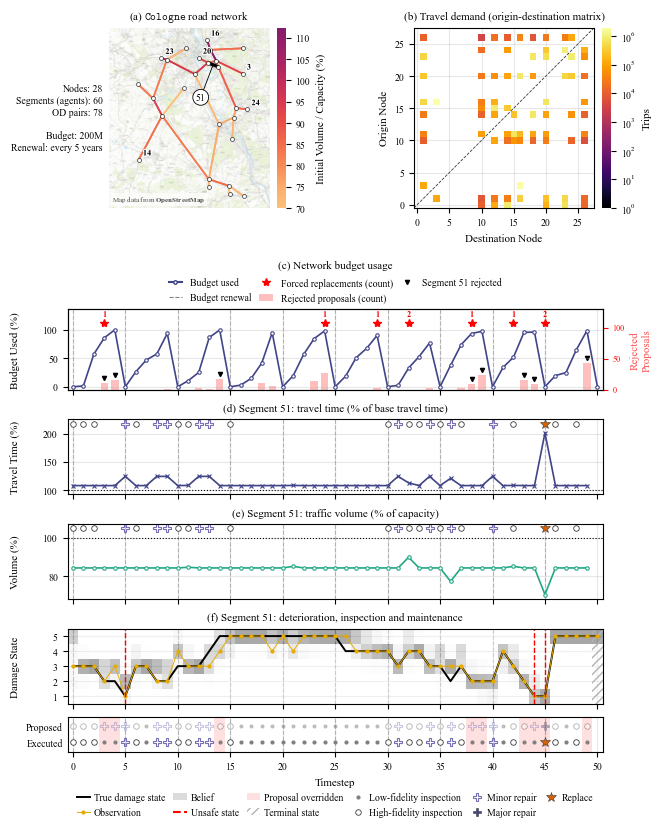

In [5]:
# Figure
fig = plt.figure(figsize=(6.5, 8.2), layout="constrained")
fig_top, fig_bottom = fig.subfigures(2, 1, height_ratios=[1, 2.35])
ax_map, ax_od = fig_top.subplots(1, 2)
plot_map(ax_map)
plot_od_matrix(ax_od)
gs = fig_bottom.add_gridspec(5, 1, height_ratios=[0.8, 0.75, 0.75, 0.75, 0.35])
plot_budget(fig_bottom.add_subplot(gs[0]))
plot_segment_series(
    fig_bottom.add_subplot(gs[1]),
    ep["travel_times"][:, segment] / np.asarray(env.initial_btts)[segment],
    DARK, "x",
    "Travel Time (%)",
    f"(d) Segment {segment}: travel time (% of base travel time)",
)
plot_segment_series(
    fig_bottom.add_subplot(gs[2]),
    ep["traffic_volumes"][:, segment] / np.asarray(env.initial_capacities)[segment],
    TEAL, "o", "Volume (%)",
    f"(e) Segment {segment}: traffic volume (% of capacity)",
)
ax_det = fig_bottom.add_subplot(gs[3])
plot_deterioration(ax_det)
plot_action_strip(fig_bottom.add_subplot(gs[4], sharex=ax_det))
fig_bottom.align_ylabels()

# Next to the other paper figures. Only the basemap is raster: 300 dpi keeps the PDF ~0.5 MB
fig.savefig("plotting/figures/Figure_11.pdf", dpi=300, bbox_inches="tight")
plt.show()